# Multimodal Similarity Search Service

## Dataset preparation

In [25]:
import pandas as pd

metadata_path = "data/abo-images-small/images/metadata/images.csv.gz"

In [26]:
metadata = pd.read_csv(metadata_path, compression="gzip")
metadata.head()

,image_id,height,width,path
0,010-mllS7JL,106,106,14/14fe8812.jpg
1,01dkn0Gyx0L,122,122,da/daab0cad.jpg
2,01sUPg0387L,111,111,d2/d2daaae9.jpg
3,1168jc-5r1L,186,186,3a/3a4e88e6.jpg
4,11RUV5Fs65L,30,500,d9/d91ab9cf.jpg


In [27]:
# Get valid image paths
import os

images_dir = "data/abo-images-small/images/small"

metadata["full_path"] = metadata["path"].apply(
    lambda path: os.path.join(images_dir, path)
)
filtered_metadata = metadata[metadata["full_path"].apply(os.path.isfile)]

len(filtered_metadata)

398212

In [28]:
# Keep only images with at least 1000 pixels of width and height

filtered_metadata = filtered_metadata[
    (filtered_metadata["height"] >= 1000) & (filtered_metadata["width"] >= 1000)
]

len(filtered_metadata)

342878

## Model Selection

[clip-ViT-B-32](https://huggingface.co/sentence-transformers/clip-ViT-B-32) will be used:

* vector size = 512
* `ViT` = Vision Transformer
* `B-32` = Base model with patch size == 32

## Database Setup

In [5]:
from sqlalchemy.engine import URL
from sqlalchemy import create_engine

db_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password="password",
    host="localhost",
    port=5555,
    database="similarity_search_service_db",
)

engine = create_engine(db_url)

In [15]:
# Create a database table definition for storing image embeddings

from typing import List
from pgvector.sqlalchemy import Vector
from sqlalchemy import String
from sqlalchemy.orm import DeclarativeBase, Mapped, mapped_column


# Create the base class for the table definition
class Base(DeclarativeBase):
    __abstract__ = True


class Img(Base):
    __tablename__ = "multimodal_images"
    __table_args__ = {"extend_existing": True}

    VECTOR_LENGTH: int = 512

    id: Mapped[int] = mapped_column(primary_key=True)
    image_path: Mapped[str] = mapped_column(String(256))
    embedding: Mapped[List[float]] = mapped_column(Vector(VECTOR_LENGTH))


# Create table
Base.metadata.create_all(engine)

## Image Vectorization

In [17]:
import joblib
import torch
from PIL import Image
from sentence_transformers import SentenceTransformer
from tqdm.notebook import tqdm
from sqlalchemy.orm import Session
from itertools import batched

MAX_IMAGES = 512
BATCH_SIZE = joblib.cpu_count(only_physical_cores=True)

device = "cuda" if torch.cuda.is_available() else "cpu"
model = SentenceTransformer("sentence-transformers/clip-ViT-B-32", device=device)


def insert_images(engine, images):

    with Session(engine) as session:
        for image in images:
            session.add(image)
            session.commit()


def vectorize_images(engine, model):

    paths = metadata["full_path"][:MAX_IMAGES]

    with tqdm(total=MAX_IMAGES) as pbar:
        for images_paths_batch in batched(paths, BATCH_SIZE):
            images = [Image.open(path) for path in images_paths_batch]

            # calculate embeddings
            embeddings = [model.encode(image) for image in images]

            # create Img instances for all images in batch
            imgs = [
                Img(image_path=path, embedding=embedding)
                for path, embedding in zip(images_paths_batch, embeddings)
            ]

            # insert all batch images
            insert_images(engine, imgs)
            # update pbar
            pbar.update(len(imgs))


vectorize_images(engine, model)

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

  0%|          | 0/512 [00:00<?, ?it/s]

## Search and results display

In [19]:
import matplotlib.pyplot as plt
from sqlalchemy import select


class ImageSearch:
    def __init__(self, engine, model):
        self.engine = engine
        self.model = model

    def __call__(self, image_description: str, k: int):
        found_images = self.find_similar_images(image_description, k)
        self.display_images(found_images)

    def find_similar_images(self, image_description: str, k: int):
        image_embedding = model.encode(image_description)

        query = (
            select(Img.image_path)
            .order_by(Img.embedding.cosine_distance(image_embedding))
            .limit(k)
        )

        with Session(self.engine) as session:
            result = session.execute(query).scalars().all()

        return result

    def display_images(self, images):

        k = len(images)

        fig, axes = plt.subplots(1, k, figsize=(15, 5))

        for i, img_path in enumerate(images):
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].axis("off")
            axes[i].set_title(f"Image {i + 1}")

        plt.show()

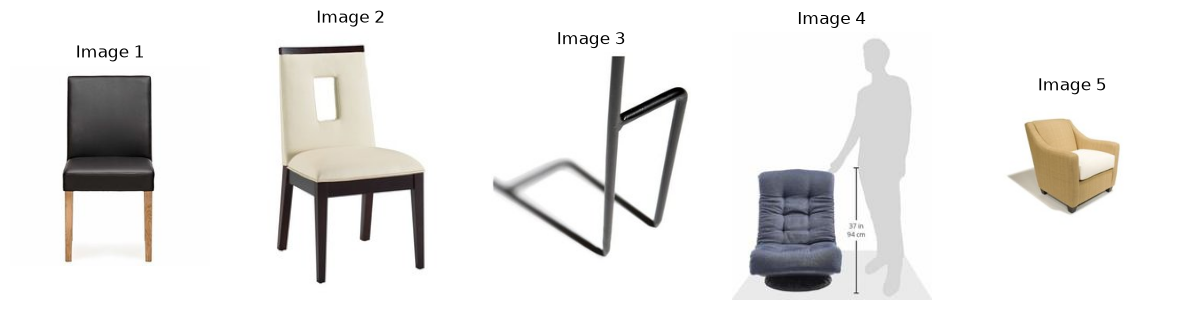

In [20]:
image_search = ImageSearch(engine, model)
image_search("grey chair", k=5)

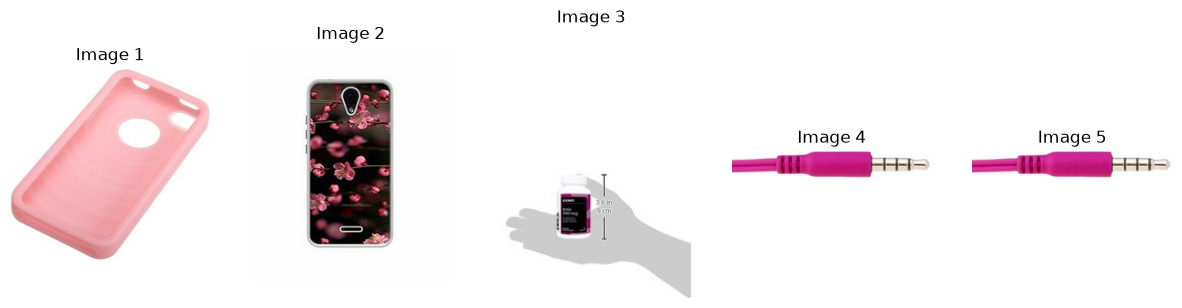

In [23]:
image_search = ImageSearch(engine, model)
image_search("pink mobile phone", k=5)

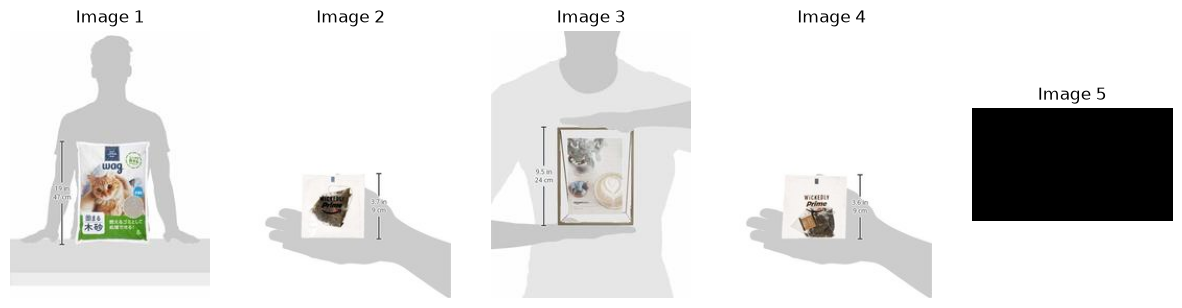

In [24]:
image_search = ImageSearch(engine, model)
image_search("cat", k=5)

* Results are relevant as long as samples similar to the requested data are present in the database
* Results are more accurate for larger MAX_IMAGES values